In [13]:
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Input, Conv1D, Dense, Multiply, Add, LayerNormalization, GlobalAveragePooling1D, Reshape, Dropout, Concatenate, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.layers import MultiHeadAttention
from tensorflow.keras.utils import plot_model
import seaborn as sns
from sklearn.metrics import classification_report, roc_curve, auc

In [15]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
#Load and preprocess dataset
df = pd.read_csv('/content/gdrive/MyDrive/soil_data2.csv')

In [17]:
df.head()

,Longitude,Latitude,Porosity,Permeability_mm_hr,Hydraulic Conductivity (m/s),Drainage_Density,Slope_degree,Slope_Length,Aspect,b1_Color_Relief,...,Soil_Temp_°C,Organic_Matter_Content_%,Topographic_Wet_Index,Stream_Pow_Index,RUSLE_LS_Factor,Aquifer_Material,Aquifer_Type,Aquifer_Depth_m,GWL,Label
0,76.71432,10.09414,95.735849,0.500323,1.390000e-07,20331.452700,7.159159,4350.0,110.772255,90,...,30.729,81.8900,9.625263,1249.625488,60.554551,2,1,90,4.491692,0
1,77.22363,10.23431,95.698113,0.432296,1.200000e-07,6822.271572,25.526939,11640.0,309.494507,97,...,30.098,52.5820,10.253804,4772.381836,149.706463,1,1,118,7.745352,0
2,77.20145,10.25270,95.735849,0.502308,1.400000e-07,16545.016460,7.853086,3390.0,86.633537,35,...,30.098,39.6520,9.303348,1047.144897,58.295093,3,1,60,5.251609,0
3,76.98110,9.93440,95.584906,0.557913,1.550000e-07,27586.592150,14.722307,1260.0,24.590118,1,...,31.088,71.5460,9.368006,3546.989471,77.071438,3,1,60,2.189206,1
4,76.92815,9.64921,100.000000,0.133045,3.700000e-08,20331.452700,3.342577,1140.0,123.690063,167,...,28.237,55.5153,7.648839,619.386047,63.170797,4,1,90,6.818370,0


In [18]:
df.shape

(11155, 53)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11155 entries, 0 to 11154
Data columns (total 53 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Longitude                     11155 non-null  float64
 1   Latitude                      11155 non-null  float64
 2   Porosity                      11155 non-null  float64
 3   Permeability_mm_hr            11155 non-null  float64
 4   Hydraulic Conductivity (m/s)  11155 non-null  float64
 5   Drainage_Density              11155 non-null  float64
 6   Slope_degree                  11155 non-null  float64
 7   Slope_Length                  11155 non-null  float64
 8   Aspect                        11155 non-null  float64
 9   b1_Color_Relief               11155 non-null  int64  
 10  Hillshade                     11155 non-null  int64  
 11  Roughness                     11155 non-null  int64  
 12  b1_LULC                       11155 non-null  int64  
 13  L

In [20]:
df.describe()

,Longitude,Latitude,Porosity,Permeability_mm_hr,Hydraulic Conductivity (m/s),Drainage_Density,Slope_degree,Slope_Length,Aspect,b1_Color_Relief,...,Soil_Temp_°C,Organic_Matter_Content_%,Topographic_Wet_Index,Stream_Pow_Index,RUSLE_LS_Factor,Aquifer_Material,Aquifer_Type,Aquifer_Depth_m,GWL,Label
count,11155.000000,11155.000000,11155.000000,11155.000000,1.115500e+04,11155.000000,11155.000000,1.115500e+04,11155.000000,11155.000000,...,11155.000000,11155.000000,11155.000000,1.115500e+04,11155.000000,11155.000000,11155.000000,11155.000000,11155.000000,11155.000000
mean,77.013264,9.892292,96.339846,0.431198,1.198651e-07,20331.452698,18.378348,1.294767e+04,171.637088,98.341282,...,29.321573,61.879352,9.368006,3.786445e+03,83.690985,2.281488,1.043568,97.855939,4.491692,0.315195
std,0.170648,0.860112,1.333454,0.115152,3.201154e-08,12961.474320,9.175905,1.183975e+05,98.813565,75.156388,...,1.250896,14.261140,2.152540,3.254088e+04,95.944439,0.862531,0.204141,26.227166,2.363474,0.464614
min,76.625900,9.295560,95.094340,0.133045,3.700000e-08,139.071188,0.328135,3.000000e+01,0.458359,1.000000,...,25.281000,37.410800,3.471123,2.400001e-01,0.088247,1.000000,1.000000,60.000000,0.587219,0.000000
25%,76.925790,9.610340,95.735849,0.423510,1.180000e-07,11278.151630,11.925902,1.740000e+03,86.295372,26.000000,...,28.633000,53.444000,8.957614,3.856101e+02,25.468319,2.000000,1.000000,60.000000,2.988282,0.000000
50%,77.020000,9.890660,95.886792,0.460284,1.280000e-07,19863.275660,18.046667,6.810000e+03,171.191995,98.000000,...,29.428000,57.581600,9.571800,1.914687e+03,77.071438,2.000000,1.000000,118.000000,4.491692,0.000000
75%,77.160000,10.150000,96.113208,0.500302,1.390000e-07,25577.150415,23.702040,1.200000e+04,245.725555,161.000000,...,30.212000,67.580800,10.532387,3.546989e+03,105.319283,3.000000,1.000000,118.000000,5.371727,1.000000
max,77.390940,95.820000,100.000000,0.624085,1.730000e-07,100020.564300,68.988052,4.916700e+06,359.518524,254.000000,...,33.453000,130.506800,17.777660,1.671846e+06,3304.547164,4.000000,2.000000,118.000000,40.002689,1.000000


/tmp/ipykernel_598/4006143072.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=df, palette='PuBuGn')


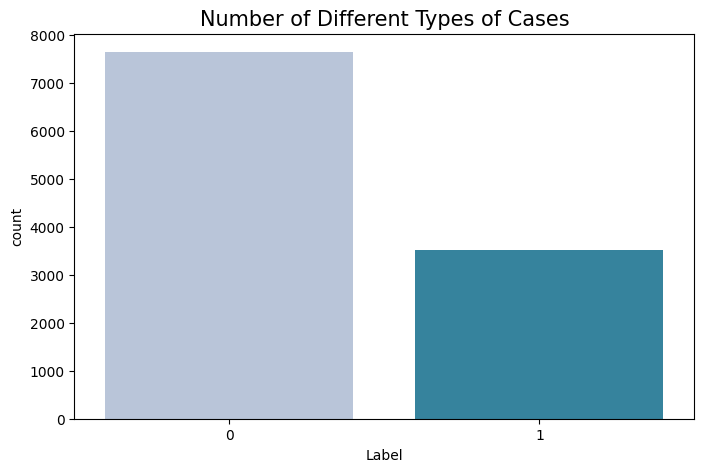

In [21]:
plt.figure(figsize=(8,5))
sns.countplot(x='Label', data=df, palette='PuBuGn')
plt.title('Number of Different Types of Cases', fontsize=15)
plt.show()

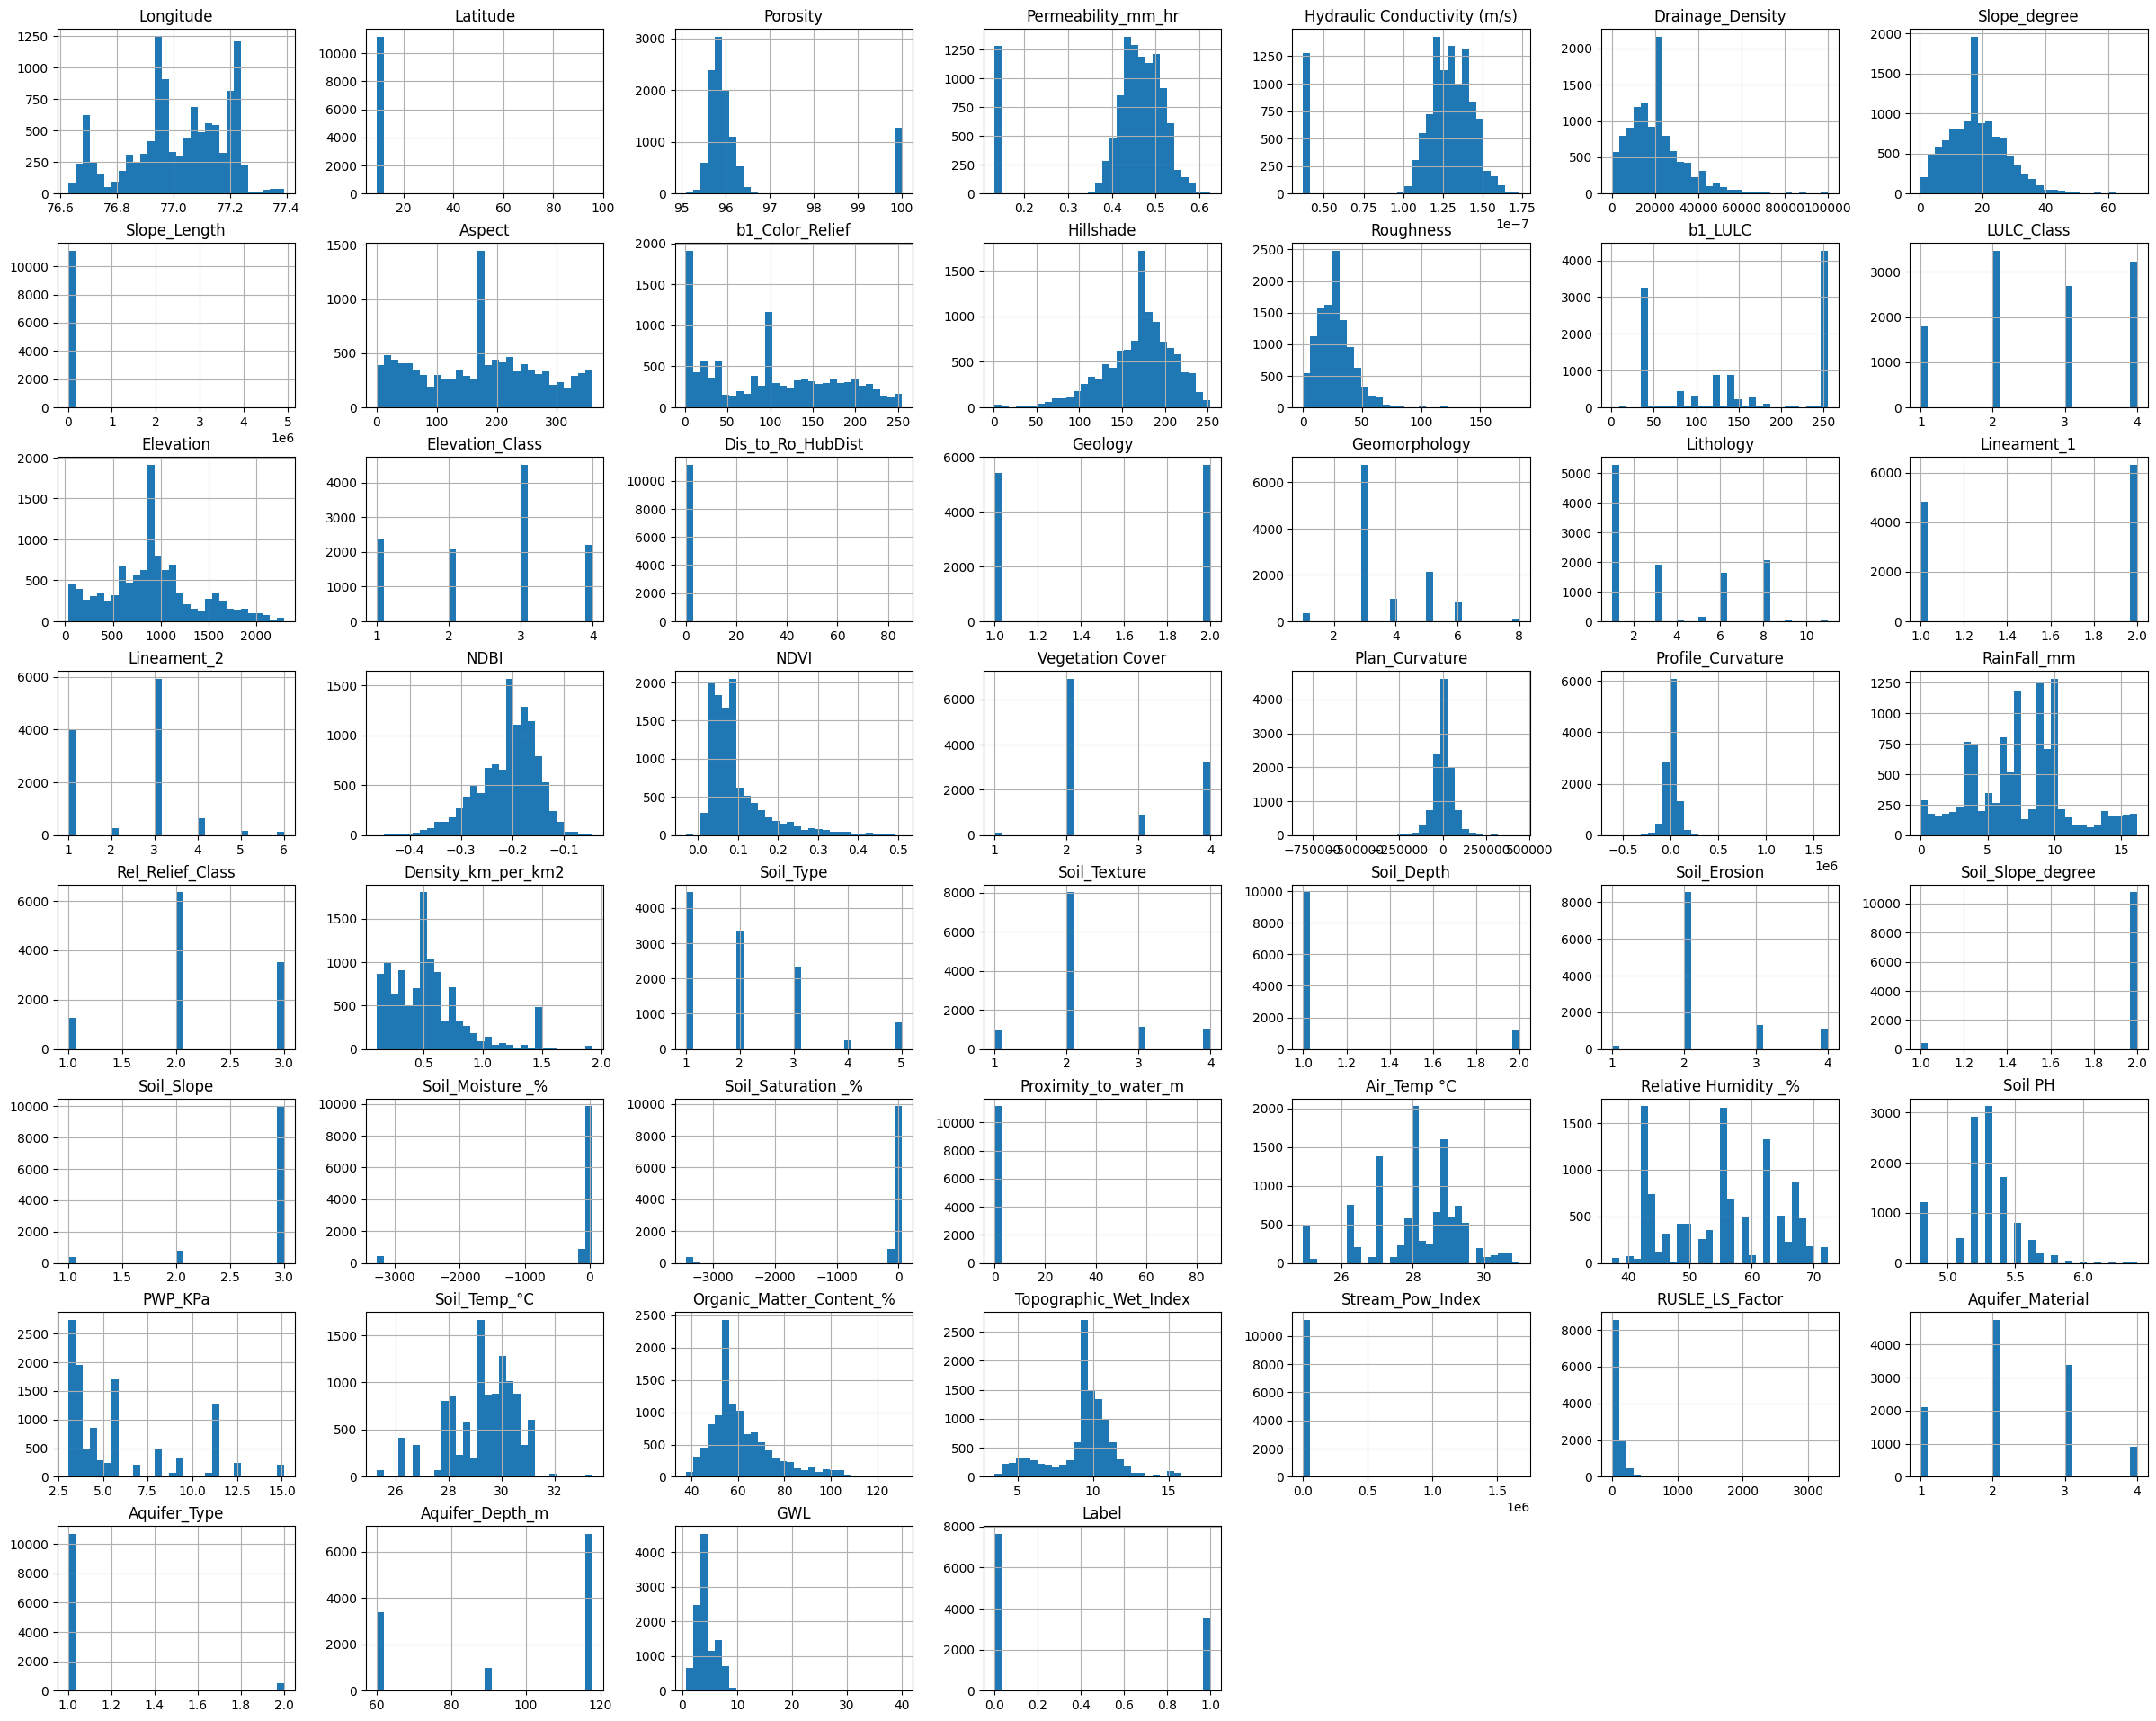

In [22]:
df.hist(figsize=(30,24),bins = 30)
plt.title("Features Distribution")
plt.show()

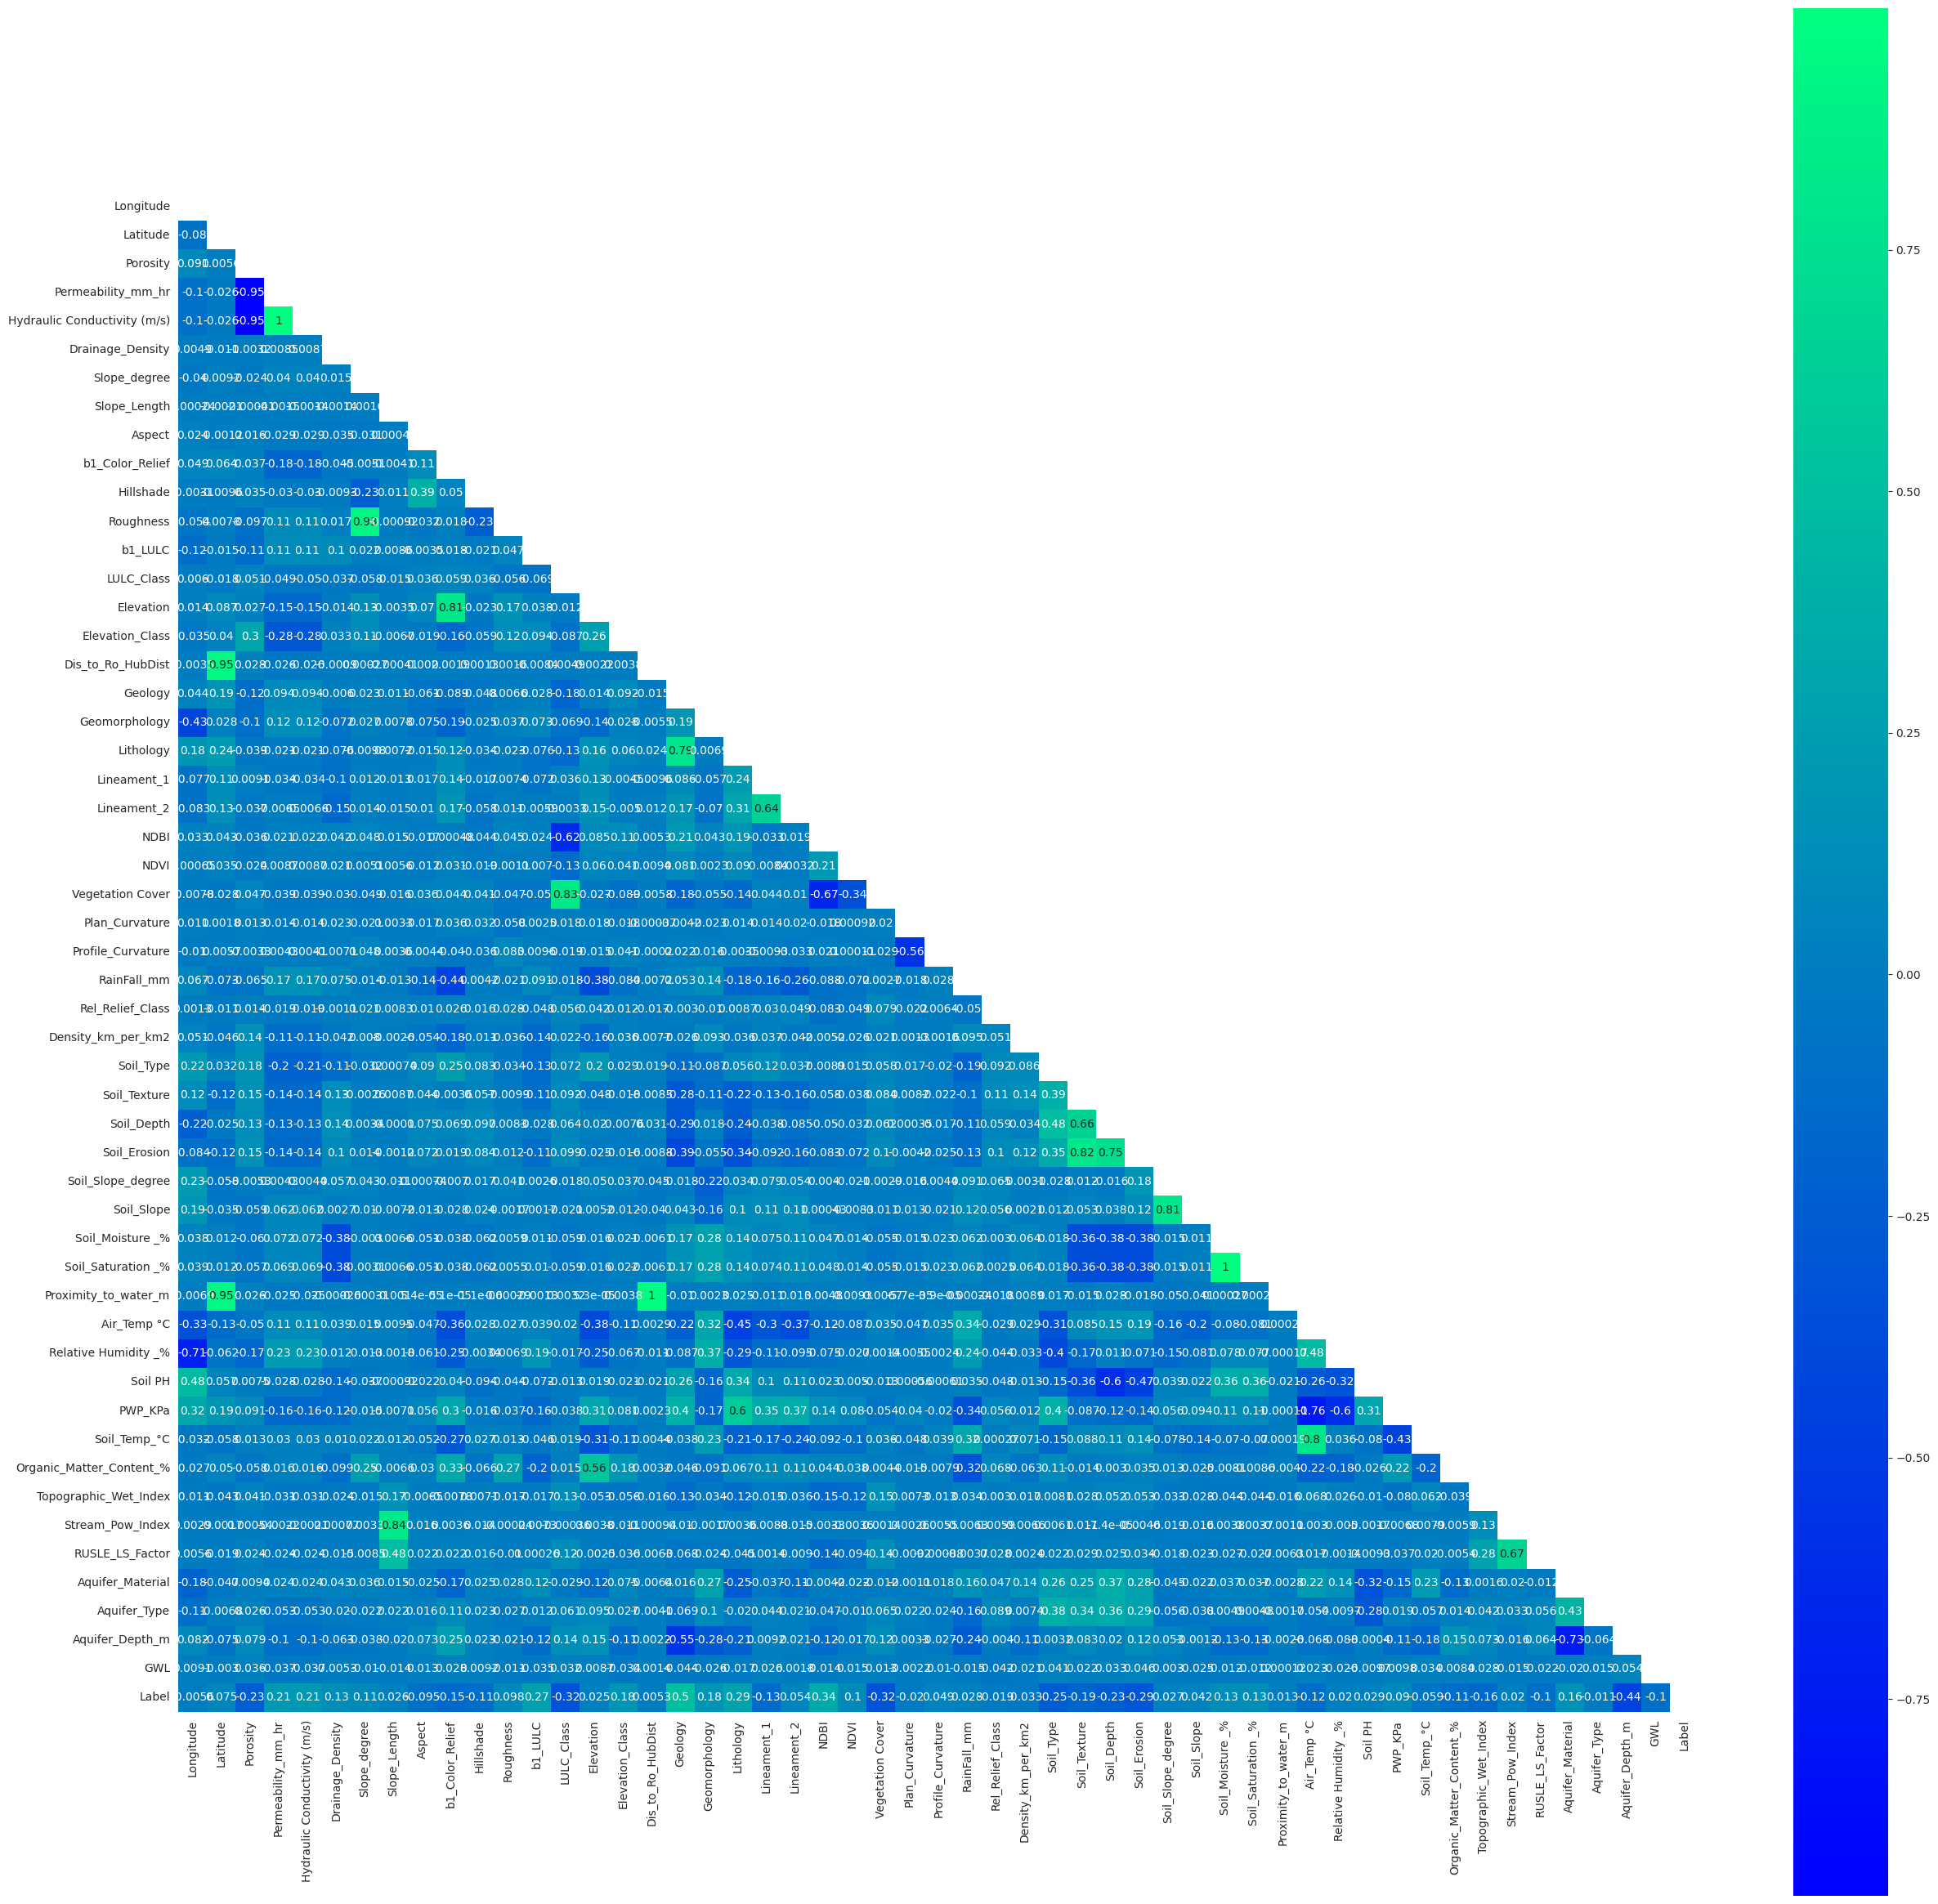

In [23]:
plt.figure(figsize=(30,30))
corr=df.corr()
mask = np.zeros_like(corr)
mask[np.triu_indices_from(mask)] = True
with sns.axes_style("white"):
    ax = sns.heatmap(corr, mask=mask,square=True, annot=True, cmap='winter')

In [24]:
# Separate features and labels
X = df.drop(columns=['Label', 'Longitude', 'Latitude']).values
y = df['Label'].values

In [25]:
# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [26]:
T = 10
X_seq = np.repeat(X_scaled[:, np.newaxis, :], T, axis=1)

In [27]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_seq, y, test_size=0.2, random_state=42, stratify=y)

**Proposed Hybrid GCN-Transformer Model**

In [28]:
# Gated Convolution Network
def GatedConvNetwork(x, filters):
    f = Conv1D(filters, kernel_size=3, padding='same', activation='tanh')(x)
    g = Conv1D(filters, kernel_size=3, padding='same', activation='sigmoid')(x)
    return Multiply()([f, g])

# Transformer Encoder
def transformer_encoder(x, head_size=64, num_heads=2, ff_dim=128, dropout=0.1):
    attn = MultiHeadAttention(num_heads=num_heads, key_dim=head_size, dropout=dropout)(x, x)
    x = LayerNormalization(epsilon=1e-6)(x + attn)
    x = BatchNormalization()(x)
    ff = Dense(ff_dim, activation='relu')(x)
    ff = Dropout(dropout)(ff)
    ff_out = Dense(x.shape[-1])(ff)
    return LayerNormalization(epsilon=1e-6)(x + ff_out)

# Build Hybrid Model
def build_model(input_shape=(10, 36)):
    inputs = Input(shape=input_shape)
    gcu = GatedConvNetwork(inputs, filters=64)
    trans = transformer_encoder(inputs)
    fusion = Concatenate()([gcu, trans])
    pooled = GlobalAveragePooling1D()(fusion)
    dense = Dense(128, activation='relu')(pooled)
    drop = Dropout(0.3)(dense)
    output = Dense(1, activation='sigmoid')(drop)
    return Model(inputs, output)

In [29]:
# Compile and train
model = build_model(input_shape=X_train.shape[1:])
optimizer = tf.keras.optimizers.Adam(learning_rate=0.00001)
model.compile(optimizer= optimizer, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 10, 50)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 10, 50)    │     26,034 │ input_layer[0][0… │
│ (MultiHeadAttentio… │                   │            │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 10, 50)    │          0 │ input_layer[0][0… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 10, 50)    │        100 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 10, 50)    │        200 │ layer_normalizat… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 10, 128)   │      6,528 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 10, 128)   │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10, 50)    │      6,450 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 10, 64)    │      9,664 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 10, 64)    │      9,664 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 10, 50)    │          0 │ batch_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 10, 64)    │          0 │ conv1d[0][0],     │
│                     │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 10, 50)    │        100 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 10, 114)   │          0 │ multiply[0][0],   │
│ (Concatenate)       │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 114)       │          0 │ concatenate[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     14,720 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │        129 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 73,589 (287.46 KB)

 Trainable params: 73,489 (287.07 KB)

 Non-trainable params: 100 (400.00 B)

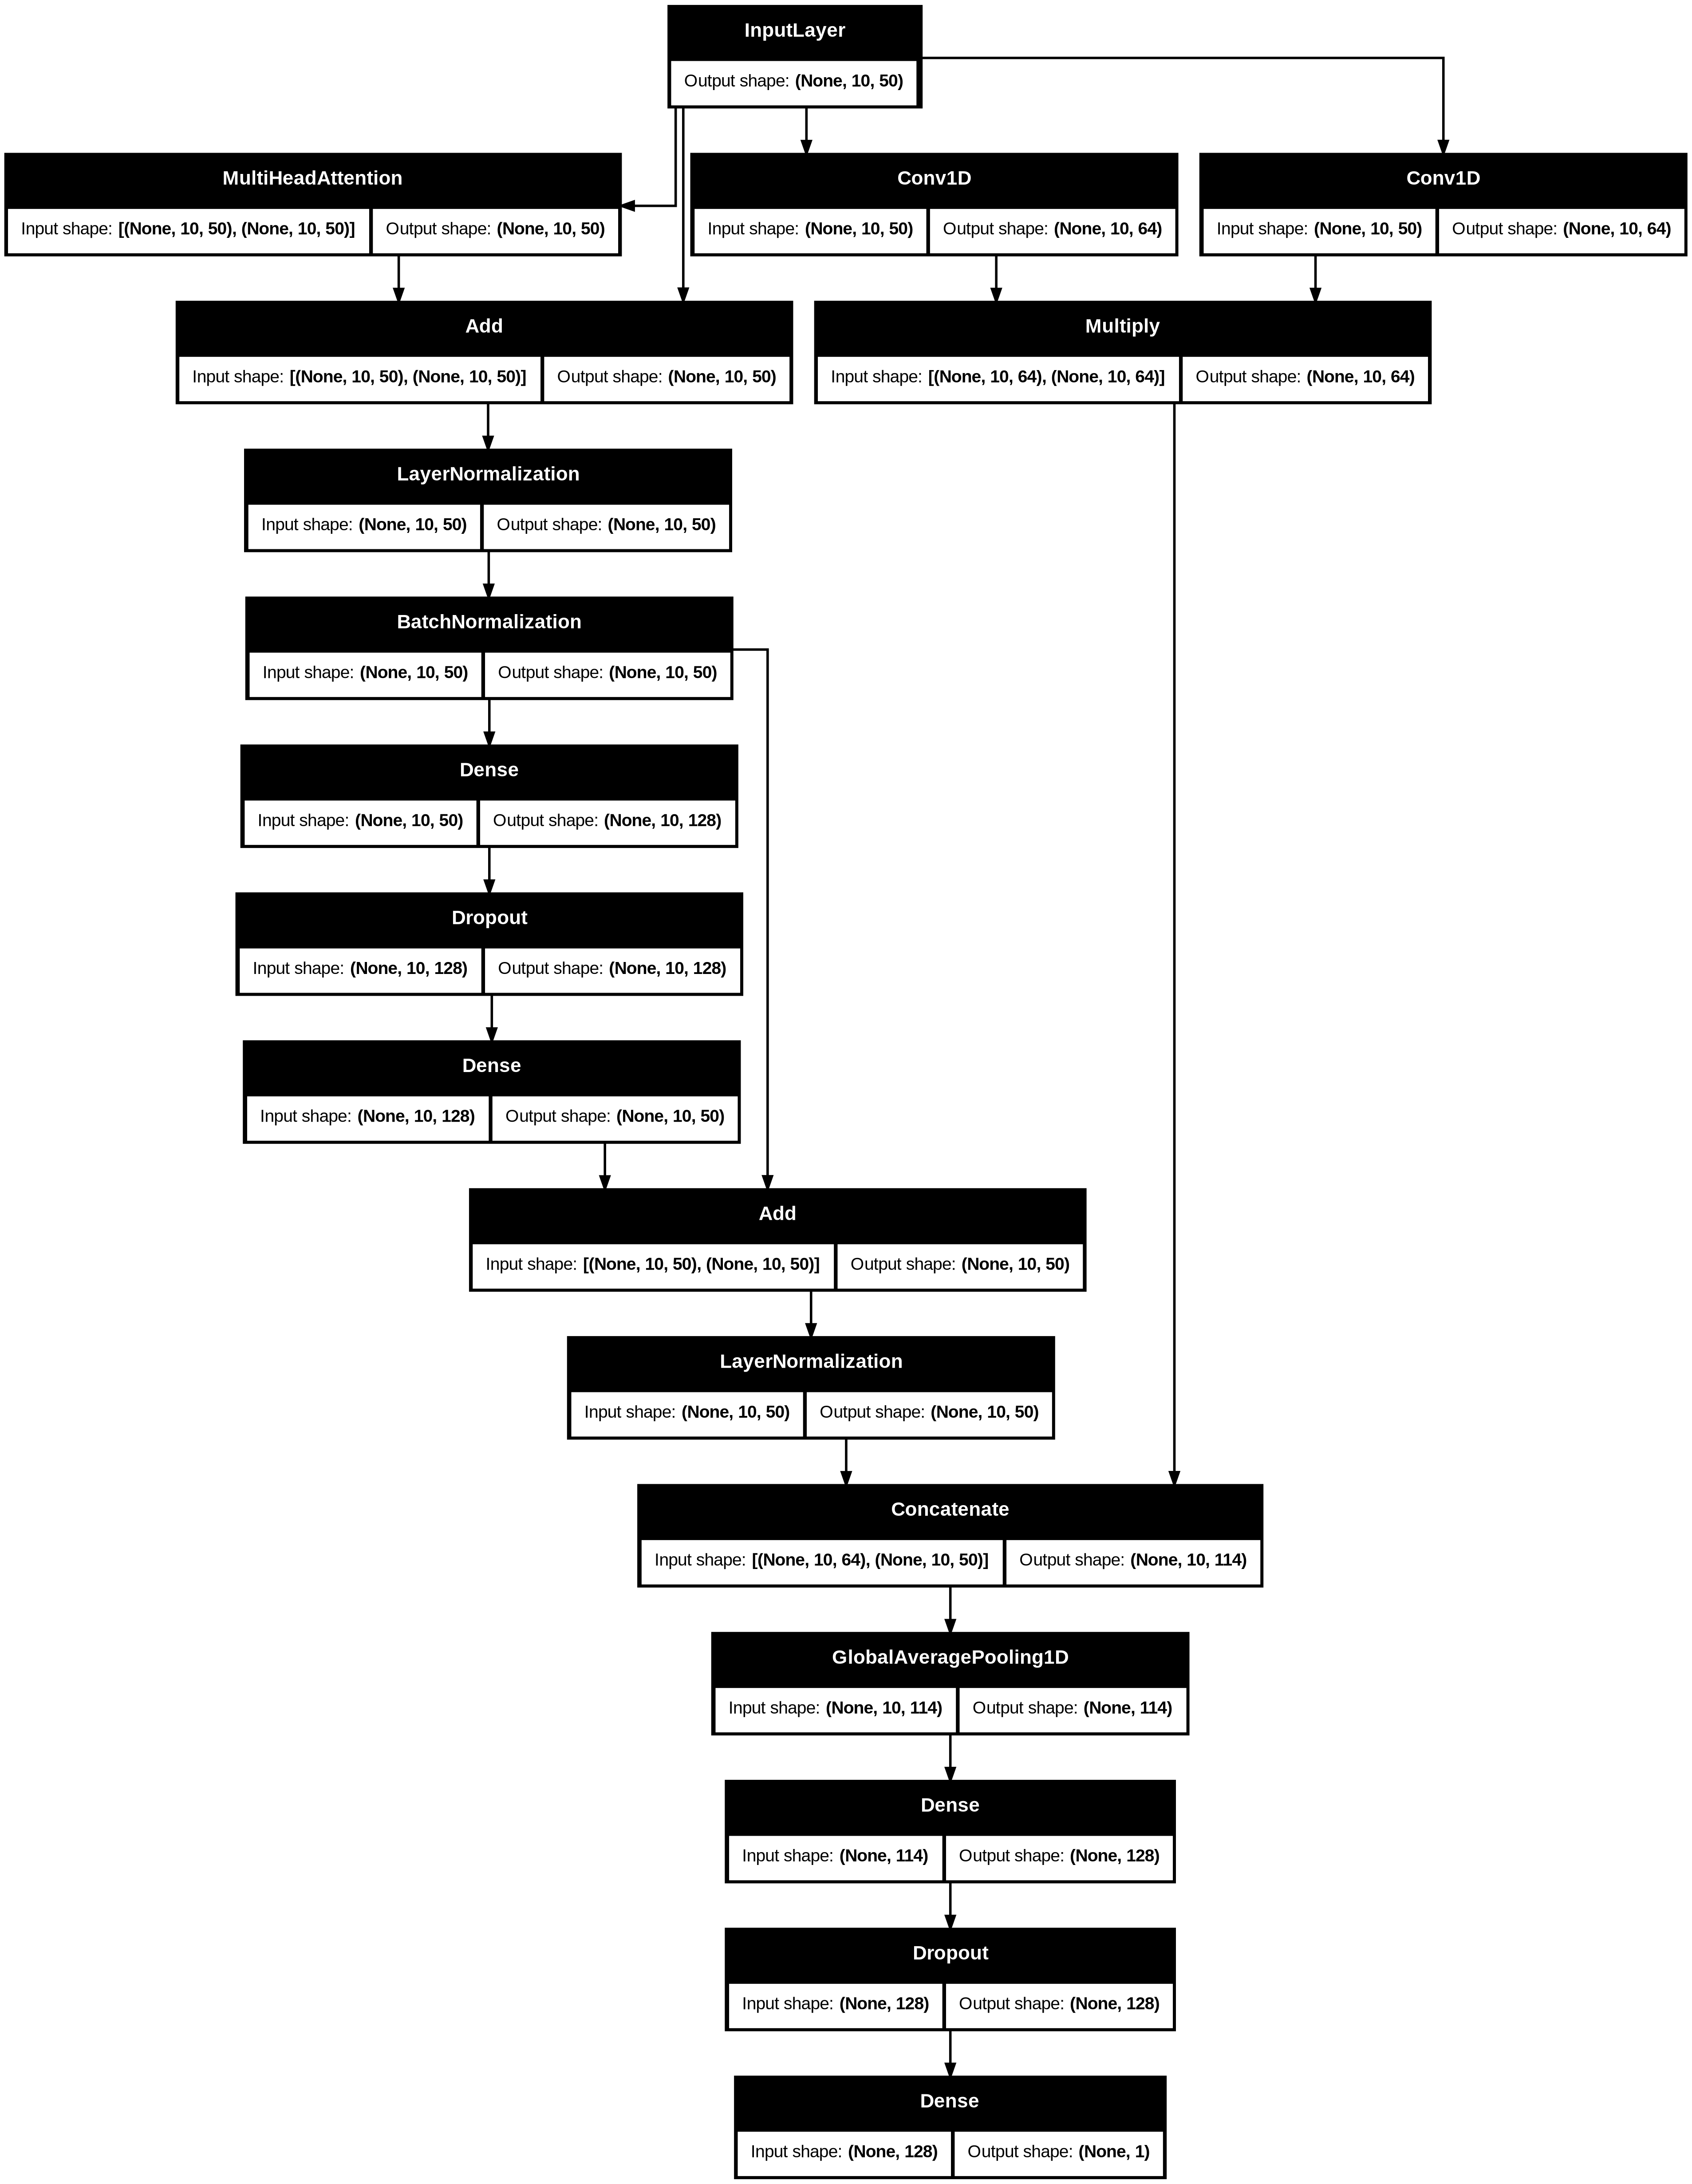

In [30]:
plot_model(model, to_file='model.png', show_shapes=True)

In [31]:
history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=100, batch_size=16)

Epoch 1/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 30s 27ms/step - accuracy: 0.6757 - loss: 0.5956 - val_accuracy: 0.8270 - val_loss: 0.4673
Epoch 2/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8231 - loss: 0.4363 - val_accuracy: 0.8821 - val_loss: 0.3642
Epoch 3/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8590 - loss: 0.3620 - val_accuracy: 0.8974 - val_loss: 0.3081
Epoch 4/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8768 - loss: 0.3171 - val_accuracy: 0.9054 - val_loss: 0.2729
Epoch 5/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8898 - loss: 0.2890 - val_accuracy: 0.9144 - val_loss: 0.2505
Epoch 6/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8960 - loss: 0.2681 - val_accuracy: 0.9184 - val_loss: 0.2325
Epoch 7/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9040 - loss: 0.2503 - val_accuracy: 0.9234 - val_loss: 0.2185
Epoch 8/100
558/558 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9089 - loss: 0.2416 - val_ac

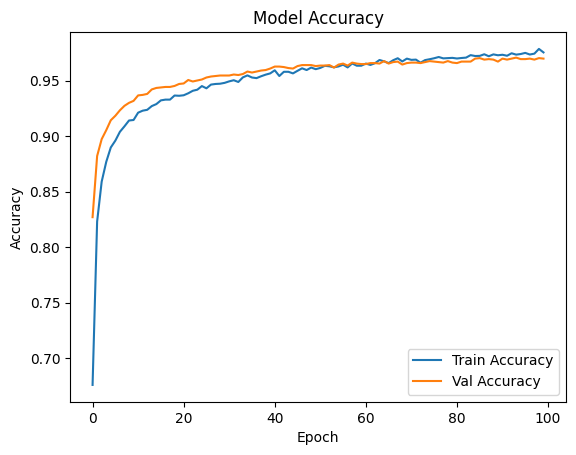

In [32]:
# Plot Accuracy and Loss
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


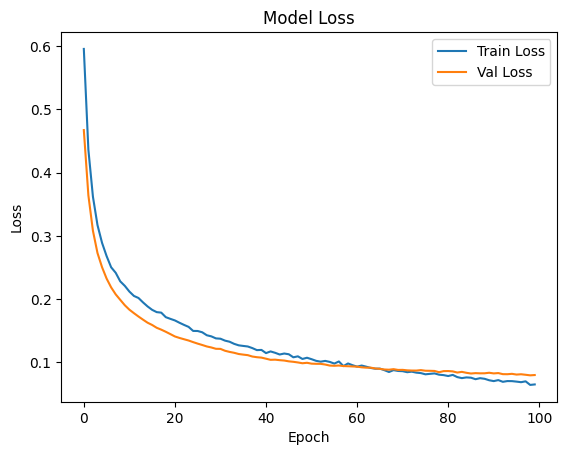

In [33]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [34]:
# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_acc}')

70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.9700 - loss: 0.0800
Test accuracy: 0.9699686169624329


In [35]:
y_pred = model.predict(X_test)

70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step


In [36]:
# Classification report
y_pred_classes = (y_pred > 0.5).astype(int)
y_true_classes = y_test.astype(int)

print(classification_report(y_true_classes, y_pred_classes, target_names=["No Risk", "Land Slide"]))

              precision    recall  f1-score   support

     No Risk       0.98      0.98      0.98      1528
  Land Slide       0.95      0.95      0.95       703

    accuracy                           0.97      2231
   macro avg       0.97      0.97      0.97      2231
weighted avg       0.97      0.97      0.97      2231



In [37]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
cm = confusion_matrix(y_true_classes, y_pred_classes)
Accuracy_score = accuracy_score(y_true_classes, y_pred_classes)
print("Accuracy Score:", Accuracy_score*100)
print("Misclassification Score:", 100-(Accuracy_score*100))
print('Precision Score:',precision_score(y_true_classes, y_pred_classes,average='weighted'))
print('Recall Score:',recall_score(y_true_classes, y_pred_classes, average='weighted'))
print('F1 Score:',f1_score(y_true_classes, y_pred_classes, average='weighted'))

Accuracy Score: 96.99686239354548
Misclassification Score: 3.0031376064545157
Precision Score: 0.9699575204881404
Recall Score: 0.9699686239354549
F1 Score: 0.9699628485161956


Text(70.72222222222221, 0.5, 'Predicted')

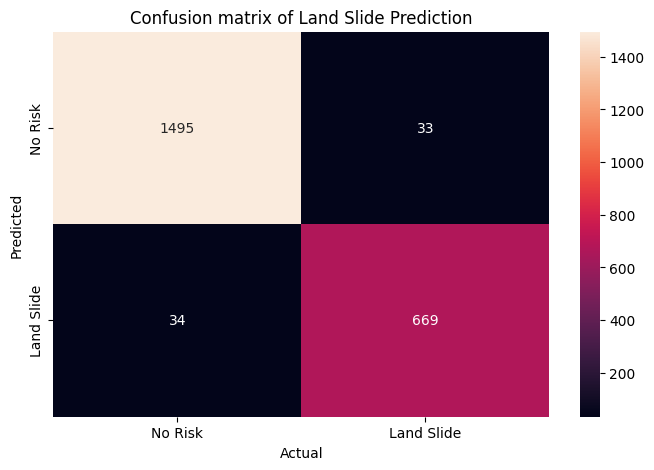

In [38]:
Index = ["No Risk","Land Slide"]
column = ["No Risk","Land Slide"]
from sklearn.metrics import confusion_matrix
plt.figure(figsize=(8,5))
cm = pd.DataFrame(data=confusion_matrix(y_true_classes, y_pred_classes),index=Index,columns=column)
plt.title("Confusion matrix of Land Slide Prediction")
sns.heatmap(cm, annot=True,fmt="d")
plt.xlabel("Actual")
plt.ylabel("Predicted")

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


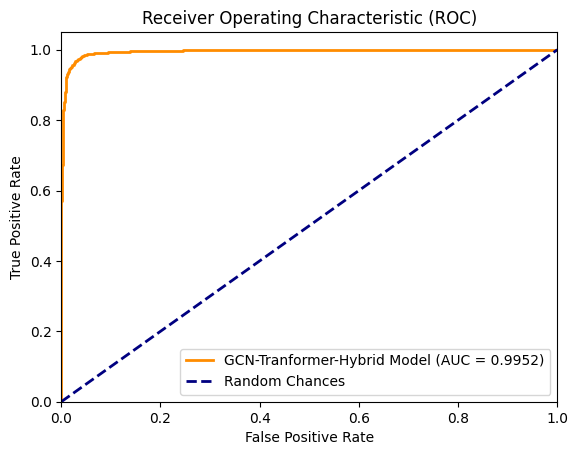

In [39]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt # Import matplotlib

# Function to plot the ROC curve
def plot_roc_curve(y_test, y_pred_prob):
    # Ensure y_test is in the correct format
    y_test_int = y_test.astype(int).flatten()
    y_pred_prob_flat = y_pred_prob.flatten()

    # Compute ROC curve and ROC area for each class
    fpr, tpr, _ = roc_curve(y_test_int, y_pred_prob_flat)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='GCN-Tranformer-Hybrid Model (AUC = %0.4f)' % roc_auc) # Added AUC to label
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Chances')  # Diagonal line for random guess
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.show()

# Call the function to plot ROC curve
y_pred_prob = model.predict(X_test)  # Get predicted probabilities
plot_roc_curve(y_test, y_pred_prob)

In [40]:
# Ensure y_pred_classes and y_test are 1D arrays
y_pred_classes_flat = y_pred_classes.flatten() if y_pred_classes.ndim > 1 else y_pred_classes
y_test_flat = y_test.flatten() if y_test.ndim > 1 else y_test

# Create a DataFrame to display original and predicted labels
results_df = pd.DataFrame({'Original Label': y_test_flat, 'Predicted Label': y_pred_classes_flat})

# Map numerical labels to descriptive names
label_mapping = {0: "No Risk", 1: "Land Slide"}
results_df['Original Label'] = results_df['Original Label'].map(label_mapping)
results_df['Predicted Label'] = results_df['Predicted Label'].map(label_mapping)

display(results_df)

,Original Label,Predicted Label
0,No Risk,No Risk
1,Land Slide,Land Slide
2,Land Slide,Land Slide
3,No Risk,No Risk
4,No Risk,No Risk
...,...,...
2226,No Risk,No Risk
2227,No Risk,No Risk
2228,Land Slide,Land Slide
2229,No Risk,No Risk


In [41]:
# Separate features and labels from the original dataframe
X_original = df.drop(columns=['Label']).values
y_original = df['Label'].values

X_original_seq = np.repeat(X_original[:, np.newaxis, :], T, axis=1) # shape: (samples, 10, 34)
X_train_original_seq, X_test_original_seq, y_train_original, y_test_original = train_test_split(X_original_seq, y_original, test_size=0.2, random_state=42, stratify=y_original)

# Reshape the original test sequence data to (samples, T * features) for the DataFrame
num_samples_test_seq = X_test_original_seq.shape[0]
num_timesteps_seq = X_test_original_seq.shape[1]
num_features_seq = X_test_original_seq.shape[2]

X_test_original_reshaped = X_test_original_seq.reshape(num_samples_test_seq, num_timesteps_seq * num_features_seq)

# Get original feature names (excluding the target 'Label')
original_feature_names = df.drop(columns=['Label']).columns.tolist()

# Create column names using original feature names and timestep
feature_columns_original = [f'{feature}_timestep_{j}' for feature in original_feature_names for j in range(num_timesteps_seq)]

# Create a DataFrame with original feature values
results_df_original_values = pd.DataFrame(X_test_original_reshaped, columns=feature_columns_original)
y_pred_classes_flat = y_pred_classes.flatten() if y_pred_classes.ndim > 1 else y_pred_classes

results_df_original_values['Original Label'] = y_test_original
results_df_original_values['Predicted Label'] = y_pred_classes_flat


# Map numerical labels to descriptive names
label_mapping = {0: "No Risk", 1: "Land Slide"}
results_df_original_values['Original Label'] = results_df_original_values['Original Label'].map(label_mapping)
results_df_original_values['Predicted Label'] = results_df_original_values['Predicted Label'].map(label_mapping)


# Define the filename
csv_filename = '/content/test_results_with_predictions.csv'

# Save the DataFrame to CSV
results_df_original_values.to_csv(csv_filename, index=False)

print(f"Results with original values saved to {csv_filename}")

Results with original values saved to /content/test_results_with_predictions.csv


In [42]:
# Define the filename of the saved CSV
csv_filename = '/content/test_results_with_predictions.csv'

# Read the CSV file into a DataFrame
predicted_results_df = pd.read_csv(csv_filename)

# Display the head of the DataFrame
display(predicted_results_df.head(15))

,Longitude_timestep_0,Longitude_timestep_1,Longitude_timestep_2,Longitude_timestep_3,Longitude_timestep_4,Longitude_timestep_5,Longitude_timestep_6,Longitude_timestep_7,Longitude_timestep_8,Longitude_timestep_9,...,GWL_timestep_2,GWL_timestep_3,GWL_timestep_4,GWL_timestep_5,GWL_timestep_6,GWL_timestep_7,GWL_timestep_8,GWL_timestep_9,Original Label,Predicted Label
0,76.95822,9.61427,95.962264,0.462060,1.280000e-07,4214.63631,27.640064,9330.0,356.009094,165.0,...,71.3736,10.239833,3109.284180,105.762752,2.0,1.0,118.0,4.491692,No Risk,No Risk
1,77.00006,10.01743,96.037736,0.448976,1.250000e-07,20497.26748,27.101892,7110.0,129.863617,45.0,...,56.8920,9.368006,3546.989471,77.071438,1.0,1.0,118.0,4.071648,Land Slide,Land Slide
2,76.95033,9.87587,95.886792,0.532219,1.480000e-07,40621.75906,18.732338,1350.0,49.844002,1.0,...,53.6164,9.368006,3546.989471,77.071438,3.0,1.0,60.0,3.813899,Land Slide,Land Slide
3,77.14802,10.30312,96.000000,0.538059,1.500000e-07,12949.60384,20.844616,12121.0,203.838745,1.0,...,73.0976,9.368006,3546.989471,77.071438,1.0,1.0,118.0,2.554399,No Risk,No Risk
4,76.93832,9.42233,100.000000,0.133045,3.700000e-08,20331.45270,18.046667,19860.0,171.191995,98.0,...,55.5153,10.285137,13464.185550,325.314287,4.0,2.0,90.0,6.920723,No Risk,No Risk
5,77.23350,9.53221,95.811321,0.447211,1.240000e-07,47110.31480,27.021671,6390.0,20.449547,10.0,...,64.9948,10.073982,1721.578491,67.925406,2.0,1.0,118.0,4.491692,No Risk,No Risk
6,76.86000,10.03000,95.735849,0.479008,1.330000e-07,13751.94112,16.930244,12121.0,176.185928,1.0,...,63.9604,9.368006,3546.989471,77.071438,3.0,1.0,60.0,4.688517,Land Slide,Land Slide
7,76.69693,10.22016,96.188679,0.421893,1.170000e-07,16050.48849,30.650244,6510.0,111.655991,211.0,...,97.2336,9.368006,3546.989471,77.071438,2.0,1.0,118.0,2.872071,No Risk,No Risk
8,77.22668,10.21794,96.000000,0.432737,1.200000e-07,10978.98952,5.006779,11910.0,213.690064,212.0,...,63.2708,10.331426,4623.198242,142.424189,1.0,1.0,118.0,5.694938,No Risk,No Risk
9,76.95042,9.87449,95.886792,0.532219,1.480000e-07,40621.92784,18.732338,7590.0,49.844002,1.0,...,53.6164,9.368006,3546.989471,77.071438,3.0,1.0,60.0,2.796011,Land Slide,Land Slide


/tmp/ipykernel_598/608362205.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='True Label')


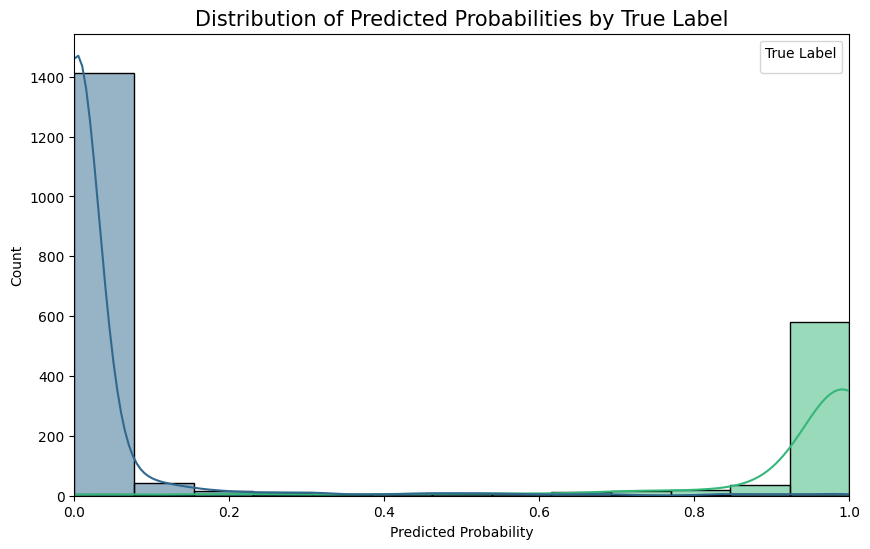

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a DataFrame for plotting probabilities
prob_df = pd.DataFrame({'Predicted Probability': y_pred.flatten(), 'True Label': y_test})

# Map numerical true labels to descriptive names for plotting
label_mapping = {0: "No Risk", 1: "Land Slide"}
prob_df['True Label'] = prob_df['True Label'].map(label_mapping)

# Plot the distribution of predicted probabilities, separated by true label
plt.figure(figsize=(10, 6))
sns.histplot(data=prob_df, x='Predicted Probability', hue='True Label', kde=True, palette='viridis', common_norm=False)
plt.title('Distribution of Predicted Probabilities by True Label', fontsize=15)
plt.xlabel('Predicted Probability')
plt.ylabel('Count')
plt.xlim([0, 1]) # Probabilities are between 0 and 1
plt.legend(title='True Label')
plt.show()

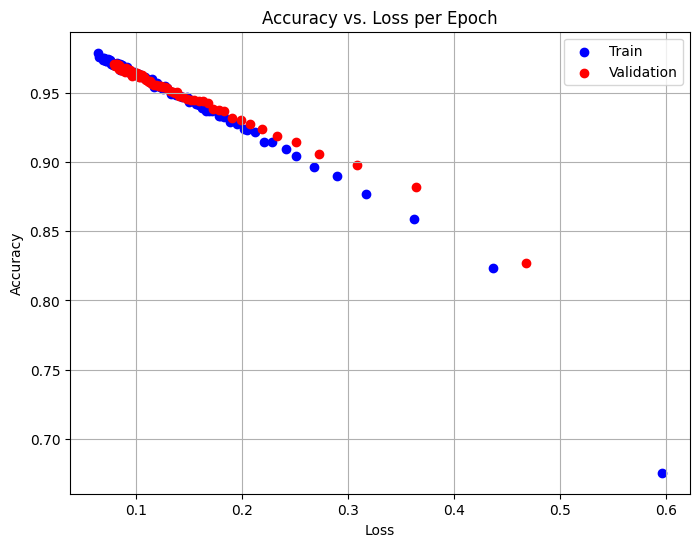

In [44]:
# scatter plot of accuracy vs loss per epoch
plt.figure(figsize=(8, 6))

# Scatter plot for training metrics
plt.scatter(history.history['loss'], history.history['accuracy'], label='Train', color='blue')

# Scatter plot for validation metrics
plt.scatter(history.history['val_loss'], history.history['val_accuracy'], label='Validation', color='red')

plt.title('Accuracy vs. Loss per Epoch')
plt.xlabel('Loss')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

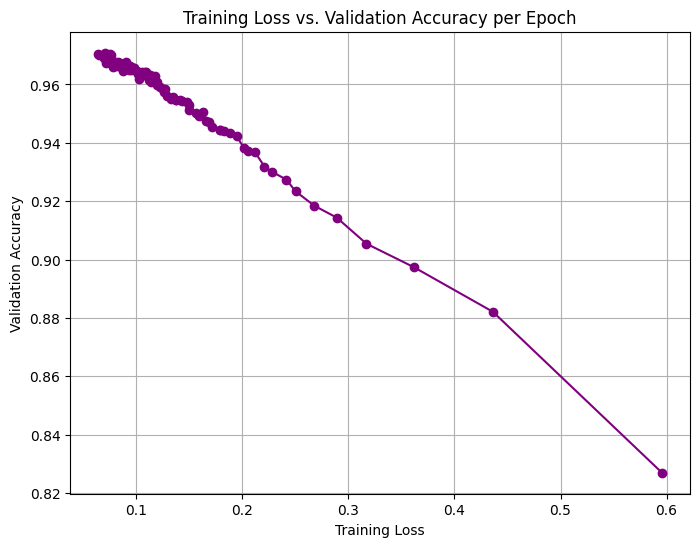

In [45]:
# plot of training loss vs validation accuracy per epoch
plt.figure(figsize=(8, 6))

plt.plot(history.history['loss'], history.history['val_accuracy'], marker='o', linestyle='-', color='purple')

plt.title('Training Loss vs. Validation Accuracy per Epoch')
plt.xlabel('Training Loss')
plt.ylabel('Validation Accuracy')
plt.grid(True)
plt.show()

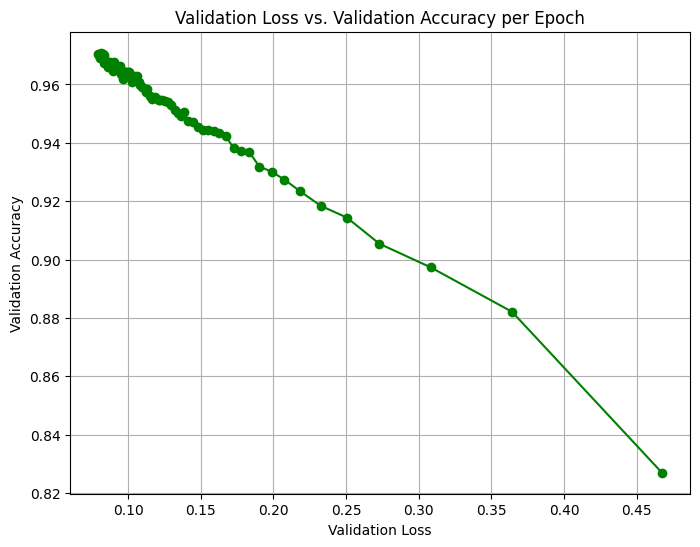

In [46]:
# plot of validation loss vs validation accuracy per epoch
plt.figure(figsize=(8, 6))

plt.plot(history.history['val_loss'], history.history['val_accuracy'], marker='o', linestyle='-', color='green')

plt.title('Validation Loss vs. Validation Accuracy per Epoch')
plt.xlabel('Validation Loss')
plt.ylabel('Validation Accuracy')
plt.grid(True)
plt.show()